# Personality Analysis

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [2]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
# Import SMOTE
from imblearn.over_sampling import SMOTE

In [4]:
#Importing the data
data_personality = pd.read_csv('personality_dataset.csv')
data_personality.head(2)

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,No,4.0,6.0,No,13.0,5.0,Extrovert
1,9.0,Yes,0.0,0.0,Yes,0.0,3.0,Introvert


In [5]:
extrovert_people = data_personality[data_personality['Personality'] == 'Extrovert']
introvert_people = data_personality[data_personality['Personality'] == 'Introvert']

print("Comparisons:")
print("Extroverts: friends circle size -> ", extrovert_people['Friends_circle_size'].mean())
print("Introverts: friends circle size -> ", introvert_people['Friends_circle_size'].mean())
print("Comparisons:")
print("Extroverts: how much do they go outside -> ", extrovert_people['Going_outside'].mean())
print("Introverts: how much do they go outside -> ", introvert_people['Going_outside'].mean())

Comparisons:
Extroverts: friends circle size ->  9.1736733287388
Introverts: friends circle size ->  3.196793002915452
Comparisons:
Extroverts: how much do they go outside ->  4.634615384615385
Introverts: how much do they go outside ->  1.2728592162554426


In [6]:
data_personality.isna().sum()

Time_spent_Alone             63
Stage_fear                   73
Social_event_attendance      62
Going_outside                66
Drained_after_socializing    52
Friends_circle_size          77
Post_frequency               65
Personality                   0
dtype: int64

In [7]:
data_personality.dropna(inplace=True)

In [8]:
data_personality.isnull().sum()

Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
Personality                  0
dtype: int64

In [9]:
data_personality.describe()

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2477.000000,2477.000000,2477.000000,2477.000000,2477.000000
mean,4.522406,3.939039,3.013726,6.239806,3.559548
std,3.491162,2.900044,2.257239,4.311365,2.927397
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,3.000000,1.000000
50%,4.000000,3.000000,3.000000,5.000000,3.000000
75%,8.000000,6.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


In [10]:
data_personality['Personality'].value_counts()

Personality
Extrovert    1274
Introvert    1203
Name: count, dtype: int64

In [11]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
data_personality.Personality = labelencoder.fit_transform(data_personality.Personality.values)
data_personality.Drained_after_socializing = labelencoder.fit_transform(data_personality.Drained_after_socializing.values)
data_personality.Stage_fear = labelencoder.fit_transform(data_personality.Stage_fear.values)

Text(0.5, 1.0, 'Personality and Stage fear')

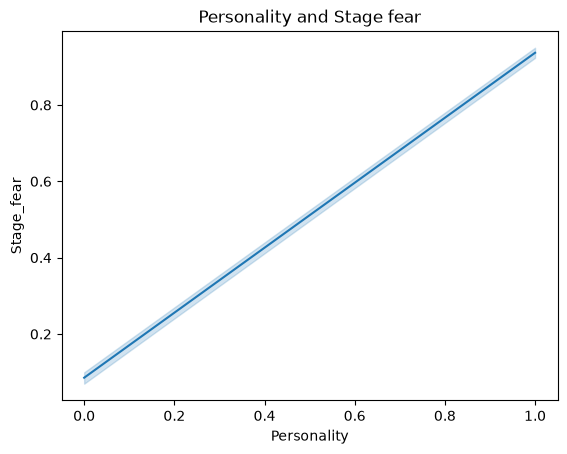

In [12]:
sns.lineplot(data=data_personality, x='Personality', y='Stage_fear')
plt.title("Personality and Stage fear")

Text(0.5, 1.0, 'Correlation among columns/variables')

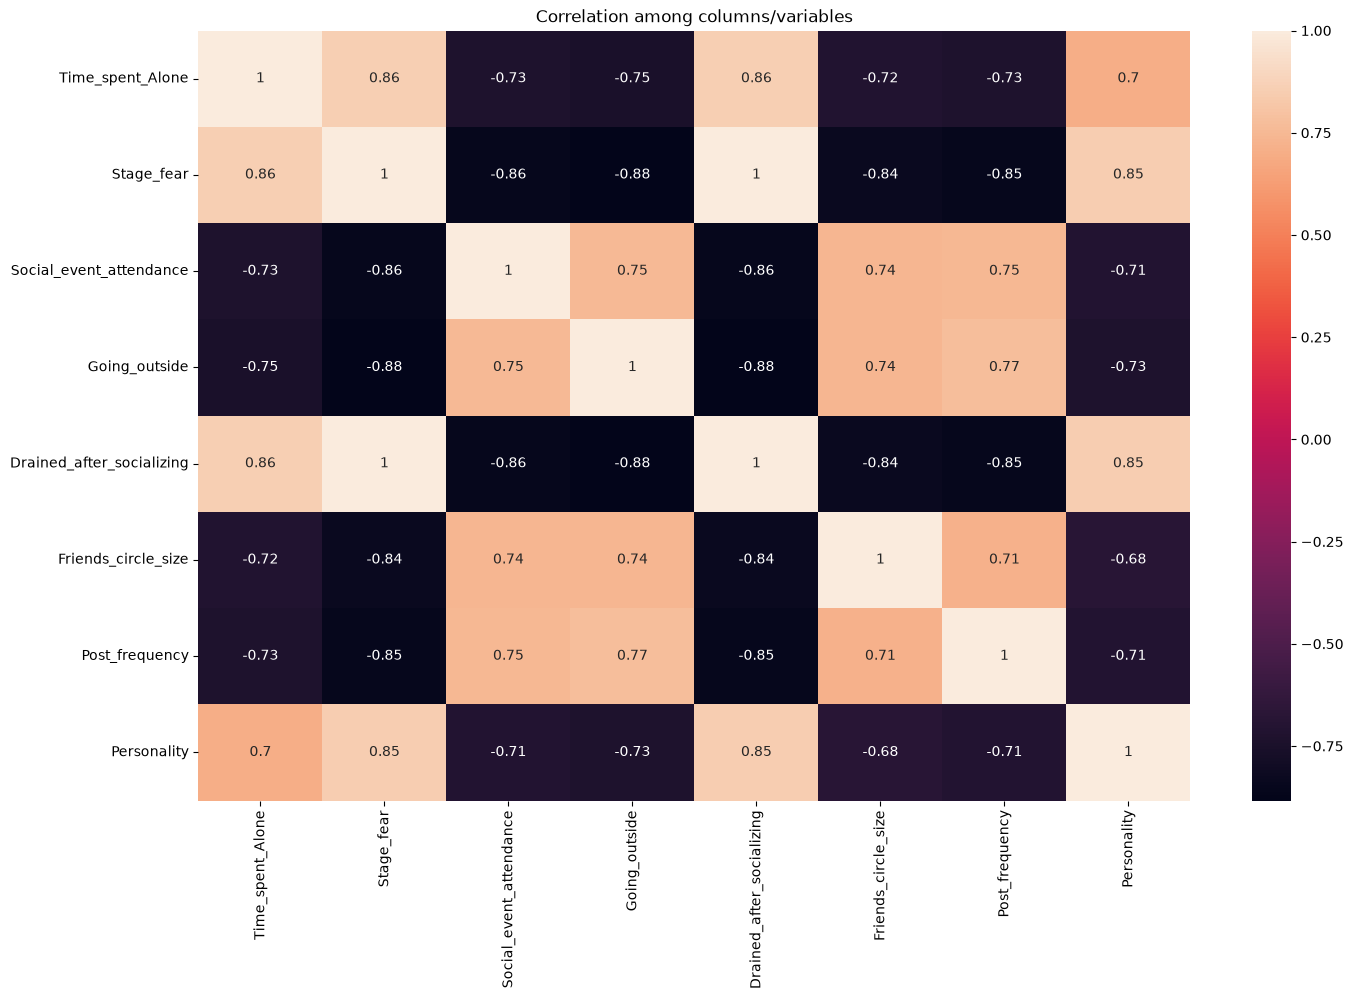

In [13]:
plt.figure(figsize=(16, 10))
sns.heatmap(data_personality.corr(), annot=True)
plt.title('Correlation among columns/variables')

#### Preparing data for Logistic Regression
Used for predicting the personality

In [14]:
X = data_personality.drop('Personality', axis=1)
Y = data_personality['Personality']

In [15]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=Y
)

In [16]:
sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [17]:
classifier = LogisticRegression(
    fit_intercept=True,
    max_iter=1000,
    random_state=42
)

# Apply SMOTE only to the training data to avoid data leakage.
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

classifier.fit(x_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [18]:
predictions = classifier.predict(x_test)

<Axes: >

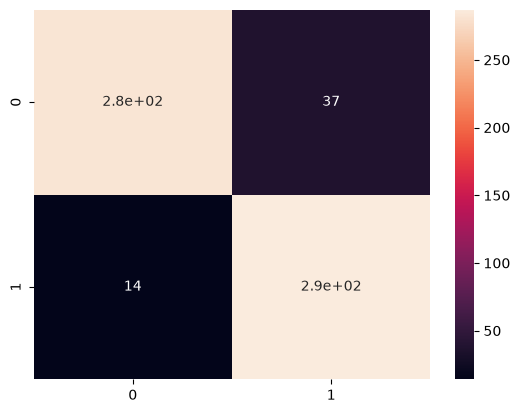

In [19]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

In [20]:
## Accuracy of the model
accuracy_score(y_test, predictions)

0.917741935483871

In [21]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.88      0.92       319
           1       0.89      0.95      0.92       301

    accuracy                           0.92       620
   macro avg       0.92      0.92      0.92       620
weighted avg       0.92      0.92      0.92       620



In [22]:
# Balanced accuracy is useful when class frequencies are not exactly equal.
balanced_accuracy = balanced_accuracy_score(y_test, predictions)
print("Balanced Accuracy: {:.4f}".format(balanced_accuracy))

Balanced Accuracy: 0.9188


## Feature importance: which variables best predict personality?

This section evaluates **all input variables** used by the Logistic Regression model.

- **Permutation importance** measures how much the model's test-set accuracy decreases when one feature is randomly shuffled. Larger values indicate greater predictive usefulness.
- **Logistic Regression coefficients** show the direction and strength of each feature's relationship with the model prediction. Because the inputs were standardized, coefficient magnitudes are on a comparable scale.

The analysis uses the held-out test set for permutation importance. SMOTE is applied only to the training set.

In [23]:
# Keep the original column names for the importance results.
feature_names = X.columns

# Permutation importance on the untouched test set.
permutation_result = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values("Importance", ascending=False)

display(permutation_importance_df)

,Feature,Importance,Std
1,Stage_fear,0.412903,0.01978
4,Drained_after_socializing,0.412903,0.01978
0,Time_spent_Alone,0.000000,0.00000
2,Social_event_attendance,0.000000,0.00000
3,Going_outside,0.000000,0.00000
5,Friends_circle_size,0.000000,0.00000
6,Post_frequency,0.000000,0.00000


In [24]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    data_personality['Personality'].to_numpy().ravel(),
    test_size=0.25,
    random_state=42,
    stratify=data_personality['Personality'].to_numpy().ravel()
)

smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [25]:
# Logistic Regression coefficients.
# For binary classification, a positive coefficient moves the prediction
# toward the class encoded as 1; a negative coefficient moves it toward class 0.
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": classifier.coef_[0],
    "Absolute_Coefficient": np.abs(classifier.coef_[0])
}).sort_values("Absolute_Coefficient", ascending=False)

display(coefficient_df)

,Feature,Coefficient,Absolute_Coefficient
1,Stage_fear,2.420063,2.420063
4,Drained_after_socializing,2.420063,2.420063
5,Friends_circle_size,0.675859,0.675859
0,Time_spent_Alone,-0.635805,0.635805
3,Going_outside,0.600482,0.600482
2,Social_event_attendance,0.454552,0.454552
6,Post_frequency,0.140921,0.140921


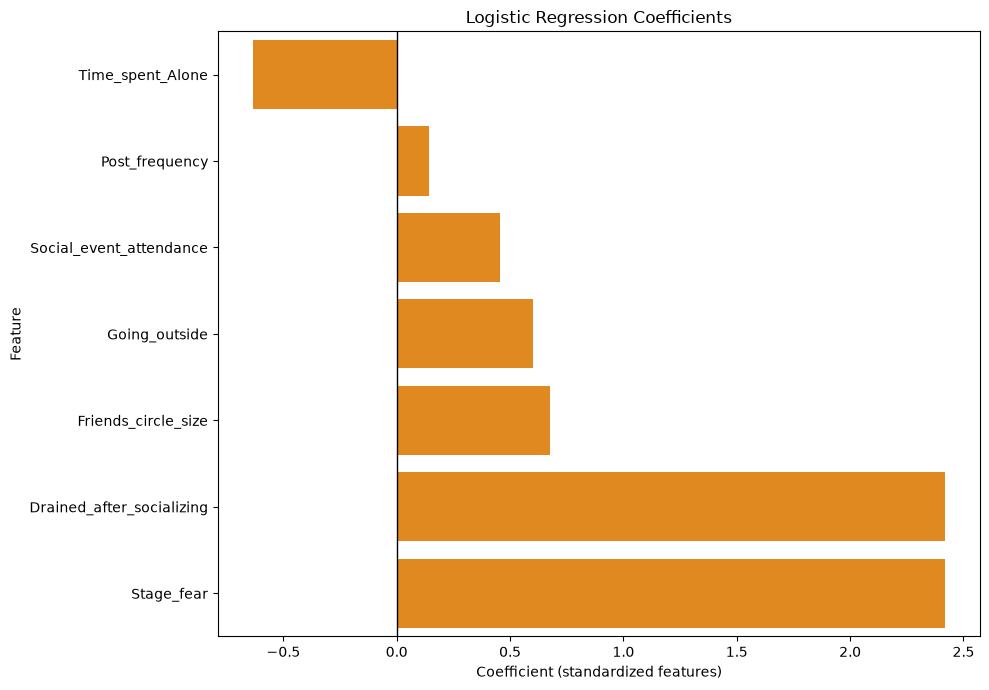

In [26]:
# Plot signed coefficients to show both magnitude and direction.
coefficient_plot = coefficient_df.sort_values("Coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=coefficient_plot,
    x="Coefficient",
    y="Feature",
    color="darkorange"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (standardized features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [27]:
# Compare both importance methods in one table.
importance_comparison = permutation_importance_df[
    ["Feature", "Importance"]
].merge(
    coefficient_df[["Feature", "Absolute_Coefficient"]],
    on="Feature"
).sort_values("Importance", ascending=False)

display(importance_comparison)

,Feature,Importance,Absolute_Coefficient
0,Stage_fear,0.412903,2.420063
1,Drained_after_socializing,0.412903,2.420063
2,Time_spent_Alone,0.000000,0.635805
3,Social_event_attendance,0.000000,0.454552
4,Going_outside,0.000000,0.600482
5,Friends_circle_size,0.000000,0.675859
6,Post_frequency,0.000000,0.140921


### How to interpret the results

1. **Permutation importance** is the primary ranking for predictive usefulness on this test set. Values near zero suggest that shuffling a variable has little effect on accuracy; negative values can occur due to sampling variability.
2. **Absolute coefficient size** describes the strength of the model's learned linear relationship after standardization. The signed coefficient indicates direction relative to the class encoded as `1`.
3. If the two rankings differ, that is not necessarily an error: permutation importance measures impact on model performance, while coefficients describe the fitted linear model.
4. These are associations used by this model, not proof that a variable causes a personality type. Correlated variables can also share or mask importance.